<font size=7 color="#5499C7" >Assignment 2: OCR</font>
- <font size=5>__Group Members__ : Kourosh Sajjadi - Kasra Noorbakhsh</font>
- <font size=5>__Student IDs__  : 810100587 - 810100230</font> 
- <font size=5>__Course__ : Computer Vision</font> 

In [15]:
import os
import random
import string
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt
from PIL import ImageFilter, ImageFont, ImageDraw, Image

OUT_DIR = "Captcha"
os.makedirs(OUT_DIR, exist_ok=True)

WIDTH, HEIGHT = 200, 100
N_SAMPLES = 10
CHARS = string.ascii_lowercase + string.digits
FONT_SIZE = 40

font = ImageFont.truetype("arial.ttf", FONT_SIZE)

<font size=7 color="#5499C7" >Part 1: Generating Data</font>

<p align="justify"><font size="6" color="#A9CCE3"><b>Sample Generation</b></font><br></p>

<p align="justify">
Here we generated 10 random samples each containing 3 characters
</p>

In [16]:
def generate_captcha(text):    
    img = Image.new("RGB", (WIDTH, HEIGHT), (255, 255, 255))
    draw = ImageDraw.Draw(img)
    
    bbox = draw.textbbox((0, 0), text, font=font)
    text_w = bbox[2] - bbox[0]
    text_h = bbox[3] - bbox[1]
    x = (WIDTH - text_w) // 2
    y = (HEIGHT - text_h) // 2
    
    draw.text((x, y), text, font=font, fill=(0, 0, 0))

    text_mask = Image.new("L", (WIDTH, HEIGHT), 255)  
    mask_draw = ImageDraw.Draw(text_mask)
    mask_draw.text((x, y), text, font=font, fill=0)

    return img

In [17]:
for i in range(N_SAMPLES):
    text = ''.join(random.choices(CHARS, k=3))
    img = generate_captcha(text)
    img.save(os.path.join(OUT_DIR, f"{text}_{i:02d}.png"))

print(f"{N_SAMPLES} samples '{OUT_DIR}'")

10 samples 'Captcha'


<p align="justify"><font size="6" color="#A9CCE3"><b>Salt and Pepper Noise</b></font><br></p>

<p align="justify">
Here we added salt and pepper noise to the samples generated and plotted them after the noise
</p>

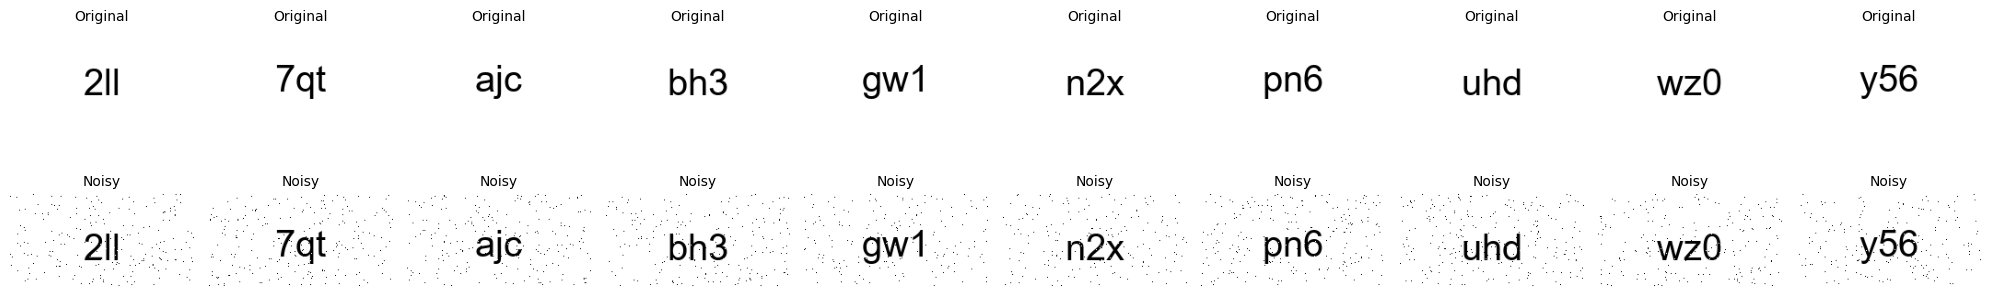

In [18]:
def add_salt_pepper_noise(image, salt_prob=0.01, pepper_prob=0.01):
    img_array = np.array(image)
    noisy_img = img_array.copy()
    
    # Salt noise (white pixels)
    salt_mask = np.random.random(img_array.shape[:2]) < salt_prob
    noisy_img[salt_mask] = [255, 255, 255] 
    
    # Pepper noise (black pixels)
    pepper_mask = np.random.random(img_array.shape[:2]) < pepper_prob
    noisy_img[pepper_mask] = [0, 0, 0]
    
    return Image.fromarray(noisy_img)

files = sorted([f for f in os.listdir(OUT_DIR) if f.endswith('.png') and not f.startswith('noisy_')])

original_images = []
noisy_images = []

for filename in files:
    original_path = os.path.join(OUT_DIR, filename)
    original_img = Image.open(original_path)
    original_images.append(original_img)
    
    noisy_img = add_salt_pepper_noise(original_img)
    noisy_images.append(noisy_img)

    noisy_filename = f"noisy_{filename}"
    noisy_img.save(os.path.join(OUT_DIR, noisy_filename))

fig, axes = plt.subplots(2, len(original_images), figsize=(20, 4))

for i in range(len(original_images)):
    axes[0, i].imshow(original_images[i])
    axes[0, i].set_title("Original", fontsize=10)
    axes[0, i].axis('off')
    
    axes[1, i].imshow(noisy_images[i])
    axes[1, i].set_title("Noisy", fontsize=10)
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

<p align="justify"><font size="6" color="#A9CCE3"><b>Blurring</b></font><br></p>

<p align="justify low">
Here we blurred the images using a 5x5 Gaussian blur kernel because it provides a smooth, natural-looking blur that simulates optical blur, with its values following a Gaussian distribution where the center pixel has the highest weight and the influence decreases smoothly for surrounding pixels; this symmetric kernel ensures uniform blurring in all directions, its normalized values that sum to 1 preserve the image's overall brightness, and the 5x5 size offers a moderate, noticeable-but-not-excessive blurring strength, making it a standard and widely used choice for image preprocessing and augmentation.
</p>

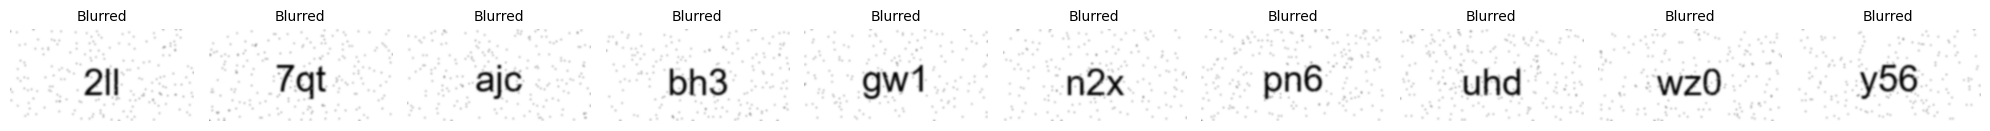

In [19]:
# Define a Gaussian blur kernel (5x5)
kernel = np.array([
    [1, 4, 7, 4, 1],
    [4, 16, 26, 16, 4],
    [7, 26, 41, 26, 7],
    [4, 16, 26, 16, 4],
    [1, 4, 7, 4, 1],
]) / 273  # Normalize so sum equals 1

def apply_kernel_blur(image, kernel):
    img_array = np.array(image)
    blurred_channels = []
    for i in range(img_array.shape[2]):  # For each RGB channel
        channel = img_array[:, :, i]
        blurred_channel = ndimage.convolve(channel, kernel)
        blurred_channels.append(blurred_channel)
    
    # Stack the blurred channels back together
    blurred_img_array = np.stack(blurred_channels, axis=2)
    return Image.fromarray(blurred_img_array.astype('uint8'))

noisy_files = [f for f in os.listdir(OUT_DIR) if f.startswith('noisy_') and f.endswith('.png')]
blurred_images = []

for filename in noisy_files:
    noisy_path = os.path.join(OUT_DIR, filename)
    noisy_img = Image.open(noisy_path)
    
    blurred_img = apply_kernel_blur(noisy_img, kernel)
    blurred_images.append(blurred_img)

    blurred_filename = f"blurred_{filename}"
    blurred_img.save(os.path.join(OUT_DIR, blurred_filename))

n_images = len(blurred_images)
fig, axes = plt.subplots(1, n_images, figsize=(20, 4))

for i in range(n_images):
    axes[i].imshow(blurred_images[i])
    axes[i].set_title("Blurred", fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()